-Este trabajo va a estar dividido de la sigiente manera.


Base de datos df = https://www.kaggle.com/datasets/tamber/steam-video-games

 1.Exploración de los datos

Realiza un análisis exploratorio del conjunto de datos que incluya:

    1.1 Dimensiones del dataset.
    1.2 Tipos de variables.
    1.3 Valores nulos.
    1.4 Registros duplicados.
    1.5 Estadísticos descriptivos.
    1.6 Visualizaciones que permitan comprender la información.

 2.Preparación de los datos

Realiza el preprocesamiento necesario para aplicar técnicas de clustering.

    2.1 Debes justificar cada decisión tomada.
  
3.Modelado

 Implementa un algoritmo de clustering, por ejemplo:

    • K-Means
    • DBSCAN
    • Clustering Jerárquico
    3.2 Justifica la elección de los algoritmos utilizados.

  4. Interpretación de los clusters

Describe cada uno de los grupos encontrados.
Puedes responder preguntas como:

    4.1 Qué caracteriza a los usuarios de este grupo?
    4.2 Son jugadores ocasionales o frecuentes?
    4.3 Presentan comportamientos similares de compra?
    4.4 Qué diferencias existen entre los clusters?
    4.5 Asigna un nombre representativo a cada segmento.
Ejemplo:
    • Jugadores Casual
    • Coleccionistas
    • Usuarios Muy Activos
    • Compradores Frecuentes

5.Recomendaciones de negocio
Con base en los segmentos encontrados, responde:

    5.1 Qué estrategia de marketing implementarías para cada grupo?
    5.2 Qué tipo de promociones recibiría cada segmento?
    5.3 Qué usuarios priorizarías para campañas de fidelización?
    5.4 Qué información adicional sería útil para mejorar la segmentación?

# Bases de Datos

In [4]:
print("Importiación del módulo desde Google Drive = [from google.colab import drive]" )

from google.colab import drive

Importiación del módulo desde Google Drive = [from google.colab import drive]


In [5]:
print("Montaje de Google Drive = drive.mount('/content/drive')")
drive.mount('/content/drive')

Montaje de Google Drive = drive.mount('/content/drive')
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [7]:
print("Carga del conjunto de datos= df = pd.read_csv('/content/drive/MyDrive/steam-200k.csv')")
df = pd.read_csv('/content/drive/MyDrive/steam-200k.csv')


Carga del conjunto de datos= df = pd.read_csv('/content/drive/MyDrive/steam-200k.csv')


# 1.Exploración de los datos

In [17]:
print("1.1 Dimensiones del dataset")
print(" ")
print(f"Número de filas: {df.shape[0]}")
print(f"Número de filas: {df.shape[1]}")
print(" ")
df.shape

1.1 Dimensiones del dataset
 
Número de filas: 199999
Número de filas: 5
 


(199999, 5)

In [18]:
print("1.1 Dimensiones del dataset")
print(" ")
print("Información detallada")
print(" ")
df.info()

1.1 Dimensiones del dataset
 
Información detallada
 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199999 entries, 0 to 199998
Data columns (total 5 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   151603712                   199999 non-null  int64  
 1   The Elder Scrolls V Skyrim  199999 non-null  object 
 2   purchase                    199999 non-null  object 
 3   1.0                         199999 non-null  float64
 4   0                           199999 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [19]:
print("1.1 Dimensiones del dataset")
print(" ")
df.head(10)

1.1 Dimensiones del dataset
 


,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
0,151603712,The Elder Scrolls V Skyrim,play,273.0,0
1,151603712,Fallout 4,purchase,1.0,0
2,151603712,Fallout 4,play,87.0,0
3,151603712,Spore,purchase,1.0,0
4,151603712,Spore,play,14.9,0
5,151603712,Fallout New Vegas,purchase,1.0,0
6,151603712,Fallout New Vegas,play,12.1,0
7,151603712,Left 4 Dead 2,purchase,1.0,0
8,151603712,Left 4 Dead 2,play,8.9,0
9,151603712,HuniePop,purchase,1.0,0


In [20]:
print("Asignación de nombres a las columnas")
df=pd.read_csv("/content/drive/MyDrive/steam-200k.csv",header=None, names=["user id","name of game","behavior","number of hours","other"])

Asignación de nombres a las columnas


In [21]:
print("1.2 Tipos de variables")
df.dtypes

1.2 Tipos de variables


,0
user id,int64
name of game,object
behavior,object
number of hours,float64
other,int64


In [22]:
print ("1.3 Valores nulos")
print(" ")
print("Número de valores nulos por columna")
df.isnull().sum()

1.3 Valores nulos
 
Número de valores nulos por columna


,0
user id,0
name of game,0
behavior,0
number of hours,0
other,0


In [23]:
print("1.3 Valores nulos")
print(" ")
print("Porcentale de valores nulos por columna")
df.isnull().mean()*100

1.3 Valores nulos
 
Porcentale de valores nulos por columna


,0
user id,0.0
name of game,0.0
behavior,0.0
number of hours,0.0
other,0.0


In [24]:
print("1.4 Registros duplicados ")
print(" ")
total_duplicados = df.duplicated().sum()
print(f"Número de registros duplicados: {total_duplicados}")

1.4 Registros duplicados 
 
Número de registros duplicados: 707


In [25]:
print("1.4 Registros duplicados ")
print(" ")
df[df.duplicated()].head(30)

1.4 Registros duplicados 
 


,user id,name of game,behavior,number of hours,other
1968,11373749,Sid Meier's Civilization IV,purchase,1.0,0
1970,11373749,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
1972,11373749,Sid Meier's Civilization IV Warlords,purchase,1.0,0
2724,56038151,Grand Theft Auto San Andreas,purchase,1.0,0
2726,56038151,Grand Theft Auto Vice City,purchase,1.0,0
2728,56038151,Grand Theft Auto III,purchase,1.0,0
3129,57103808,Sid Meier's Civilization IV,purchase,1.0,0
3556,148510973,Grand Theft Auto III,purchase,1.0,0
3562,148510973,Grand Theft Auto San Andreas,purchase,1.0,0
3575,148510973,Grand Theft Auto Vice City,purchase,1.0,0


In [26]:
print("1.4 Registros duplicados ")
print(" ")
print("Eliminación de registro duplicados")
df = df.drop_duplicates()

1.4 Registros duplicados 
 
Eliminación de registro duplicados


In [27]:
print("1.4 Registros duplicados ")
print(" ")
total_resultados=df.duplicated().sum()
print(f"Confirmación de elimianción de registros duplicados: {total_resultados}")

1.4 Registros duplicados 
 
Confirmación de elimianción de registros duplicados: 0


In [28]:
print("1.4 Registros duplicados")
print(" ")
print(f"Número de filas finales: {df.shape[0]}")
print(f"Número de filas finales: {df.shape[1]}")
print(" ")
df.shape

1.4 Registros duplicados
 
Número de filas finales: 199293
Número de filas finales: 5
 


(199293, 5)

In [29]:
print("Eliminción de columna no necesaria")
df.drop("other", axis=1, inplace=True, errors="ignore")

Eliminción de columna no necesaria


In [30]:
print("Dataset final (Inico)")
print(" ")
df.info()

Dataset final (Inico)
 
<class 'pandas.core.frame.DataFrame'>
Index: 199293 entries, 0 to 199999
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   user id          199293 non-null  int64  
 1   name of game     199293 non-null  object 
 2   behavior         199293 non-null  object 
 3   number of hours  199293 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 7.6+ MB


In [31]:
print("1.5 Estadísticos descriptivos")
print(" ")
df.describe(include="object")

1.5 Estadísticos descriptivos
 


,name of game,behavior
count,199293,199293
unique,5155,2
top,Dota 2,purchase
freq,9682,128804


In [32]:
print("1.5 Estadísticos descriptivos")
print(" ")
df.describe(include="all")

1.5 Estadísticos descriptivos
 


,user id,name of game,behavior,number of hours
count,1.992930e+05,199293,199293,199293.000000
unique,NaN,5155,2,NaN
top,NaN,Dota 2,purchase,NaN
freq,NaN,9682,128804,NaN
mean,1.037181e+08,NaN,NaN,17.934247
std,7.212048e+07,NaN,NaN,138.297952
min,5.250000e+03,NaN,NaN,0.100000
25%,4.738430e+07,NaN,NaN,1.000000
50%,8.691201e+07,NaN,NaN,1.000000
75%,1.542309e+08,NaN,NaN,1.400000


In [33]:
print("1.6 Visualizaciones que permitan comprender la información")
df_play = df[df["behavior"] == "play"]
df_purchase = df[df["behavior"] == "purchase"] # esto se realiza para darle un nombre a cada una de las variables presentes en la categoría de behavior.de esta manera es mas facil categorizar los datos.

1.6 Visualizaciones que permitan comprender la información


In [34]:
print("1.6 Visualizaciones que permitan comprender la información")

usuarios = pd.DataFrame({"juegos_comprados": df_purchase.groupby("user id")["name of game"].nunique(),"horas_totales": df_play.groupby("user id")["number of hours"].sum()}).fillna(0) # se agrupan las variables que va son mas redundantes para conocer los datos del Data set

1.6 Visualizaciones que permitan comprender la información


Figura #1 
 


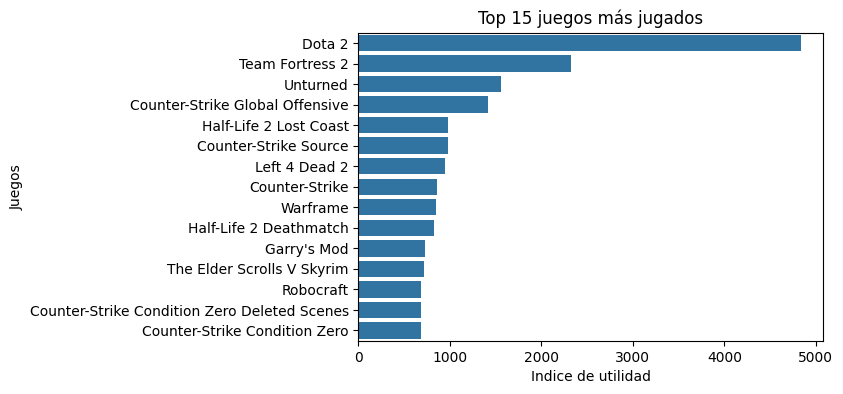

In [41]:
print("Figura #1 ")
print(" ")
plt.figure(figsize=(6, 4))
top = df_purchase["name of game"].value_counts().head(15)
sns.barplot( x=top.values, y=top.index, estimator='mean')
plt.xlabel("Indice de utilidad")
plt.ylabel("Juegos")
plt.title("Top 15 juegos más jugados")
plt.show()




Figura #2 
 


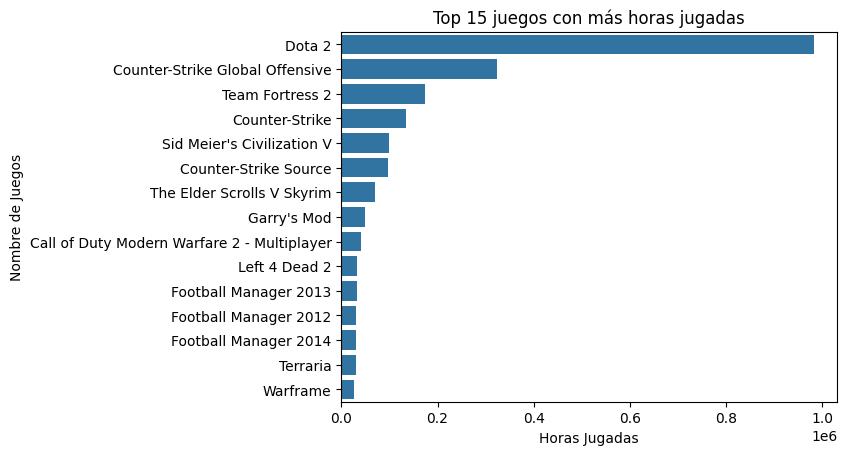

In [42]:
print("Figura #2 ")
print(" ")
top_h = df_play.groupby("name of game")["number of hours"].sum().sort_values(ascending=False).head(15)
sns.barplot(x=top_h.values, y=top_h.index)
plt.ylabel("Nombre de Juegos")
plt.xlabel("Horas Jugadas")
plt.title("Top 15 juegos con más horas jugadas")
plt.show()

Figura #3 
 


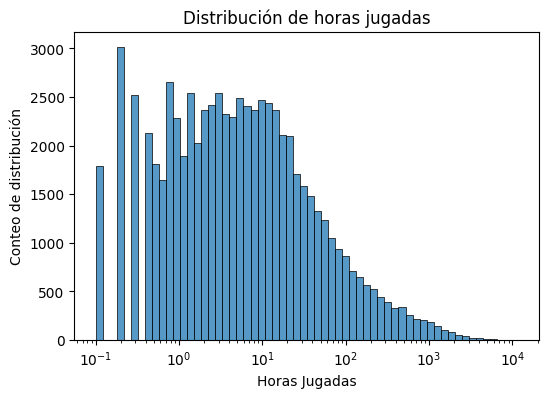

In [45]:
print("Figura #3 ")
print(" ")
plt.figure(figsize=(6, 4))
sns.histplot(df_play ['number of hours'].dropna(), bins=60,log_scale=True)
plt.ylabel("Conteo de distribución")
plt.xlabel("Horas Jugadas")
plt.title("Distribución de horas jugadas")
plt.show()



Figura #4 
 


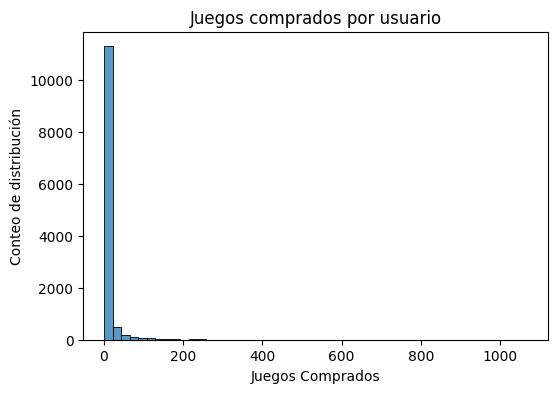

In [47]:
print("Figura #4 ")
print(" ")
plt.figure(figsize=(6, 4))
sns.histplot(usuarios["juegos_comprados"], bins=50,)
plt.ylabel("Conteo de distribución")
plt.xlabel("Juegos Comprados")
plt.title("Juegos comprados por usuario")
plt.show()


Figura #5 
 


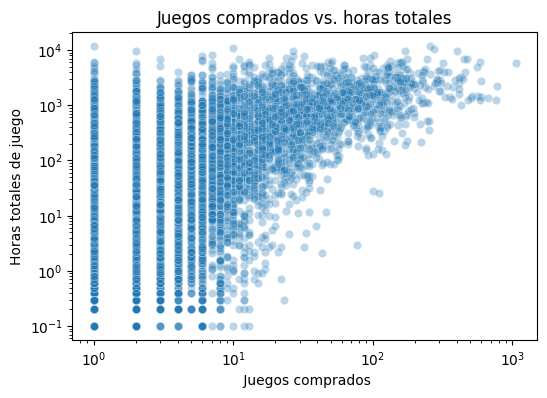

In [49]:
print("Figura #5 ")
print(" ")
plt.figure(figsize=(6, 4))
u = usuarios[usuarios["horas_totales"] > 0]
sns.scatterplot(data=u, x="juegos_comprados", y="horas_totales", alpha=0.3)
plt.ylabel("Horas totales de juego")
plt.xlabel(" Juegos comprados")
plt.title("Juegos comprados por usuario")
plt.xscale("log")
plt.yscale("log")
plt.title("Juegos comprados vs. horas totales")
plt.show()

# 2.Preparación de los datos

In [52]:
print("agrupación de datos para el clustering ")
print(" ")
usuarios = pd.DataFrame({
    "juegos_comprados": df_purchase.groupby("user id")["name of game"].nunique(),
    "juegos_jugados": df_play.groupby("user id")["name of game"].nunique(),
    "horas_totales": df_play.groupby("user id")["number of hours"].sum()
}).fillna(0) # se agrupan los datos que son necesarios para el clustering


agrupación de datos para el clustering 
 


In [54]:
print("Creación de columana adicional  ")
print(" ")
usuarios["horas_promedio"] = usuarios["horas_totales"] / usuarios["juegos_jugados"].replace(0, 1)
print("Base de datos a ser usada ")
print(" ")
usuarios.head()

Creación de columana adicional  
 
Base de datos a ser usada 
 


,juegos_comprados,juegos_jugados,horas_totales,horas_promedio
user id,,,,
5250,21,6.0,225.5,37.583333
76767,36,20.0,1227.0,61.350000
86540,82,15.0,255.0,17.000000
103360,10,0.0,0.0,0.000000
144736,8,1.0,0.1,0.100000


In [58]:
print("Filtración de datos necesarios (usuarios)")
print(" ")
usuarios.shape

Filtración de datos necesarios (usuarios)
 


(12393, 4)

In [61]:
import numpy as np

usuarios_log = np.log1p(usuarios)

usuarios_log.describe()

,juegos_comprados,juegos_jugados,horas_totales,horas_promedio
count,12393.000000,12393.000000,12393.000000,12393.000000
mean,1.480014,1.151191,3.067991,2.398231
std,1.062057,0.941669,2.434521,1.858407
min,0.693147,0.000000,0.000000,0.000000
25%,0.693147,0.693147,0.832909,0.741937
50%,1.098612,0.693147,2.674149,2.186051
75%,1.945910,1.386294,5.053695,3.688879
max,6.974479,6.212606,9.372034,9.372034


In [62]:
scaler = StandardScaler()

usuarios_escalado = pd.DataFrame(
    scaler.fit_transform(usuarios_log),
    columns=usuarios_log.columns,
    index=usuarios_log.index)

usuarios_escalado.describe().round(2)

,juegos_comprados,juegos_jugados,horas_totales,horas_promedio
count,12393.00,12393.00,12393.00,12393.00
mean,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.74,-1.22,-1.26,-1.29
25%,-0.74,-0.49,-0.92,-0.89
50%,-0.36,-0.49,-0.16,-0.11
75%,0.44,0.25,0.82,0.69
max,5.17,5.38,2.59,3.75


In [63]:
df.describe()

,user id,number of hours
count,1.992930e+05,199293.000000
mean,1.037181e+08,17.934247
std,7.212048e+07,138.297952
min,5.250000e+03,0.100000
25%,4.738430e+07,1.000000
50%,8.691201e+07,1.000000
75%,1.542309e+08,1.400000
max,3.099031e+08,11754.000000


# 3.Modelado

In [64]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [65]:
inercias = []
siluetas = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(usuarios_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(usuarios_escalado, etiquetas))

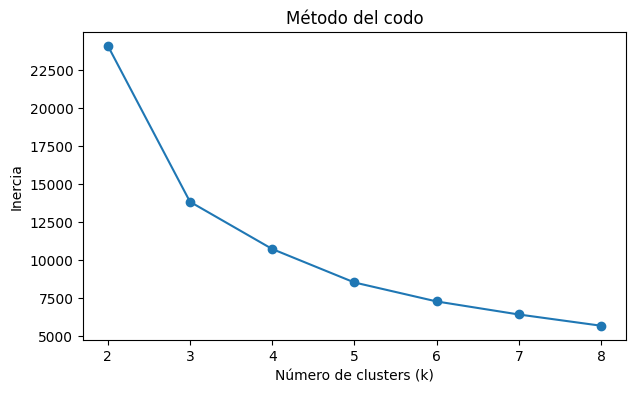

In [66]:
plt.figure(figsize=(7,4))
plt.plot(range(2, 9), inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.show()

In [67]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
usuarios["cluster"] = kmeans.fit_predict(usuarios_escalado)
score_kmeans = silhouette_score(usuarios_escalado, usuarios["cluster"])
print(f"Silhouette Score KMeans (k=4): {score_kmeans:.2f}")

Silhouette Score KMeans (k=4): 0.42


***¿Por qué estoy usando K-Mean?***

Los datos de "steam-200k.csv", en su grna mayoría son numéricos y ya están escalados. el data set tiene 12393 usuarios, y K-Means es rápido y escala bien con ese tamaño. Además, los grupos son fáciles de interpretar (cada grupo tiene un centro con valores promedio de horas y compras), lo que sirve para ponerles nombre al fnalizar el modelado.

***¿Por qué no DBSCAN?***

Marca como *“ruido”* o *outliers* a los usuarios que no encajan en zonas densas, y los usuarios en le dataset son muy extremos. POr lo tanto son un segmento que no se debe descartar para generar informaión de calidad. Además,

***¿Por qué no jerárquico?***

 Necesita calcular distancias entre todos los pares de usuarios, y con 12393 usuarios no resulta siendo el modelo mas pertinente.


# 4. Interpretación de los clusters


In [68]:
print("Valores contables de los Clusters")
print(" ")
usuarios["cluster"].value_counts().sort_index()

Valores contables de los Clusters
 


,count
cluster,
0,2118
1,4970
2,1727
3,3578


In [69]:
print("Agrupación de Clusters")
print(" ")

usuarios.groupby("cluster").mean().round(1)

Agrupación de Clusters
 


,juegos_comprados,juegos_jugados,horas_totales,horas_promedio
cluster,,,,
0,4.3,2.4,646.3,362.4
1,1.9,0.9,1.3,1.2
2,56.9,31.0,1136.1,48.1
3,3.4,2.1,30.1,18.0


***4.1 Qué caracteriza a los usuarios de este grupo?***

Se puede inferir que :

Cluster 0: Tienen pocos juegos (4.3), pero acumulan 646 horas. Se dedican y juegan  a fondo a uno o dos títulos.

Cluster 1: Compran poco (1.9 juegos) y casi no juegan (1.3 horas en total). Muchos compran un juego y nunca lo usan.

Cluster 2: Son los que más compran (57 juegos), juegan a unos 31 y acumulan 1136 horas. Tienen una biblioteca grande y la usan. (cliente target)

Cluster 3: compran pocos juegos (3.4) y juegan a unos 2, con 30 horas en total. Es un uso regular pero moderado.


***4.2 Son jugadores ocasionales o frecuentes?***

Se puede inferir que :

Cluster 0:Frecuente (muchas horas en pocos juegos)

Cluster 1:Ocasional (casi no juega)

Cluster 2:Frecuente (muchas horas en muchos juegos)

Cluster 3:Casual (juega con moderación)

***4.3 Presentan comportamientos similares de compra?***

Solo en parte:

Los clusters 0, 1 y 3 compran de forma parecida; pocos juegos (entre 2 y 4 en promedio).

El cluster 2 compra de forma muy distinta: unos 57 juegos, entre 13 y 30 veces más que los demás.

Aunque los clusters 0, 1 y 3 compran parecido, se diferencian mucho en cuánto juegan. Por eso la compra por sí sola no basta para separarlos, y las horas son las que marcan la diferencia.

***4.4 Qué diferencias existen entre los clusters?***

Compras:

El cluster 2 se separa del resto por tener una biblioteca mucho más grande.

Horas totales:

De menor a mayor, el orden es cluster 1 (1.3), cluster 3 (30), cluster 0 (646) y cluster 2 (1136).

Profundidad por juego:

El cluster 0 es el que más horas le dedica a cada juego (362 h), mientras que el cluster 2 reparte su tiempo entre muchos (48 h por juego).

Compra sin uso:

En el cluster 1 los juegos jugados (0.9) son menos que los comprados (1.9), así que muchos usuarios compran y no juegan.

***4.5 Asigna un nombre representativo a cada segmento (Cluster)***

Cluster 0:	Jugadores Dedicados (pocos juegos, muchas horas)

Cluster 1:	Jugadores Inactivos u Ocasionales

Cluster 2:	Coleccionistas Activos (muchos juegos, muchas horas)

Cluster 3:	Jugadores Casuales

# 5.Recomendaciones de negocio Con base en los segmentos encontrados

***5.1 Qué estrategia de marketing implementarías para cada grupo?***

Cluster 0:	Dedicados: Un punto importante es aprovechar que juegan mucho a pocos títulos. Ofrecer contenido extra (DLC, expansiones, ediciones especiales) de sus juegos favoritos.

Cluster 1:	Inactivos u Ocasionales	Reactivación: lograr que usen lo que ya compraron. Recordatorios de “tienes juegos sin estrenar” y recomendaciones de los juegos que ya tienen, lago simple, que sea una motivacíon para que dsifruten de sus compras.

Cluster 2:	Coleccionistas Activos: Son los clientes más valiosos. Acceso anticipado, comunidad y trato preferencial para que no se vayan. Un trato que se note que existe una preferiencia y mayor afinidad.

Cluster 3:	Casual	Engagement: aumentar su tiempo de juego y llevarlos a comprar un poco más. Recomendaciones personalizadas de juegos similares a los que ya juegan.

***5.2 Qué tipo de promociones recibiría cada segmento?***

Cluster 0:	Descuentos en DLC y expansiones de sus juegos principales, y pases de temporada.

Cluster 1:	Descuentos pequeños en juegos gratuitos o muy baratos, y ofertas de “primer juego jugado”. El objetivo es que jueguen, no que gasten.

Cluster 2:	Preventas, ofertas por volumen (por ejemplo, “compra 3 y paga 2”) y paquetes de colección.

Cluster 3:	Paquetes de 2 o 3 juegos con descuento, y ofertas de juegos parecidos a los que ya juegan.


***5.3 Qué usuarios priorizarías para campañas de fidelización?***

Los principales a priorizar son los que dan un uso alto: cluster 2 (Coleccionistas Activos) y cluster 0 (Dedicados).

Cluster 2: son solo el 14% de los usuarios, pero compran unas 13 a 30 veces más juegos que el resto y tienen muchas horas de uso. Perderlos cuesta mucho.

Cluster 0: juegan mucho y están muy comprometidos con sus títulos. Son los más propensos a comprar contenido adicional.

***5.4 Qué información adicional sería útil para mejorar la segmentación?***

Precio y gasto real: Cuánto pagó cada usuario. Hoy solo sabemos cuántos juegos compró, no cuánto dinero gastó, y un juego de 5 dólares no vale lo mismo que uno de 60.

Fechas: cuándo compró y cuándo jugó. Permitiría medir recencia y frecuencia (si el usuario sigue activo o se fue).

Género de los juegos: Acción, estrategia, deportes, etc. Permitiría recomendar con más precisión.

Datos demográficos: Edad y país, para ajustar promociones y precios regionales.

Compras dentro del juego: Microtransacciones y DLC.

Reseñas y valoraciones: Para saber si el usuario está satisfecho.

Plataforma y dispositivo: PC, consola o móvil.